
# Notebook 3 — Décision métier et analyse du retour sur investissement (ROI)

## 1. Objectif

Ce notebook vise à traduire les résultats des modèles de détection d'anomalies en éléments d'aide à la décision pour un responsable de cybersécurité.

L'objectif n'est plus d'entraîner de nouveaux modèles, mais d'évaluer leur intérêt opérationnel et économique.

Nous allons :

- comparer les performances des modèles C et D,
- estimer le coût de traitement des alertes,
- étudier différents scénarios de retour sur investissement (ROI),
- identifier les limites et les risques,
- formuler une recommandation métier argumentée.

## 2. Contexte et résultats précédents

Le projet utilise le jeu de données UNSW-NB15 pour analyser des comportements atypiques dans le trafic réseau.

Les modèles reposent sur une approche de détection d'anomalies par K-Means. Les étiquettes d'attaques permettent d'évaluer les résultats obtenus.

Sur le jeu de test :

| Indicateur | Modèle C | Modèle D |
|---|---:|---:|
| Attaques détectées | 39 409 | 44 393 |
| Attaques manquées | 79 932 | 74 948 |
| Fausses alertes | 560 | 2 862 |
| Total des alertes | 39 969 | 47 255 |
| Rappel des attaques | 33,02 % | 37,20 % |

Le modèle D détecte davantage d'attaques, mais génère également davantage de fausses alertes.

La décision devra donc prendre en compte les performances techniques, le coût opérationnel et les risques associés aux attaques non détectées.

---


In [1]:
import pandas as pd

# Résultats obtenus dans le notebook 02
resultats = pd.DataFrame({
    "Modèle": ["C", "D"],
    "Attaques détectées": [39409, 44393],
    "Attaques manquées": [79932, 74948],
    "Fausses alertes": [560, 2862],
    "Total alertes": [39969, 47255]
})

# Calcul du rappel
resultats["Rappel (%)"] = (
    resultats["Attaques détectées"]
    / (resultats["Attaques détectées"] + resultats["Attaques manquées"])
    * 100
)

# Calcul de la précision des alertes
resultats["Précision (%)"] = (
    resultats["Attaques détectées"]
    / resultats["Total alertes"]
    * 100
)

display(resultats.round(2))

,Modèle,Attaques détectées,Attaques manquées,Fausses alertes,Total alertes,Rappel (%),Précision (%)
0,C,39409,79932,560,39969,33.02,98.60
1,D,44393,74948,2862,47255,37.20,93.94



### Interprétation — Comparaison des modèles C et D

Ce tableau reprend les résultats expérimentaux obtenus dans le notebook `02_modelisation.ipynb`.

Le **rappel** mesure la proportion d'attaques détectées :

$$
\text{Rappel} = \frac{VP}{VP + FN} \times 100
$$

La **précision** mesure la proportion d'alertes correspondant réellement à une attaque :

$$
\text{Précision} = \frac{VP}{VP + FP} \times 100
$$

Le modèle D présente un rappel supérieur à celui du modèle C (37,20 % contre 33,02 %), mais une précision légèrement inférieure (93,94 % contre 98,60 %).

**Conclusion :** le modèle D améliore la détection, au prix d'un nombre plus important de fausses alertes. Le choix du modèle doit donc intégrer le coût de traitement de ces alertes.

Ces performances sont mesurées sur le jeu de test UNSW-NB15 et ne constituent pas une garantie de performance en environnement réel.

---


In [2]:
# Comparaison opérationnelle du passage de C à D

modele_C = resultats.set_index("Modèle").loc["C"]
modele_D = resultats.set_index("Modèle").loc["D"]

attaques_supplementaires = (
    modele_D["Attaques détectées"]
    - modele_C["Attaques détectées"]
)

fausses_alertes_supplementaires = (
    modele_D["Fausses alertes"]
    - modele_C["Fausses alertes"]
)

alertes_supplementaires = (
    modele_D["Total alertes"]
    - modele_C["Total alertes"]
)

ratio_detection = (
    attaques_supplementaires
    / fausses_alertes_supplementaires
)

print("Attaques supplémentaires détectées :", attaques_supplementaires)
print("Fausses alertes supplémentaires :", fausses_alertes_supplementaires)
print("Total des alertes supplémentaires :", alertes_supplementaires)
print("Ratio attaques détectées / fausses alertes supplémentaires :", round(ratio_detection, 2))

Attaques supplémentaires détectées : 4984.0
Fausses alertes supplémentaires : 2302.0
Total des alertes supplémentaires : 7286.0
Ratio attaques détectées / fausses alertes supplémentaires : 2.17



### Interprétation — Compromis opérationnel entre C et D

Le passage du modèle C au modèle D permet de détecter davantage d'attaques, mais augmente également le volume d'alertes à examiner.

Les différences sont calculées par soustraction :

$$
\Delta = \text{Résultat du modèle D} - \text{Résultat du modèle C}
$$

Le ratio entre les attaques supplémentaires détectées et les fausses alertes supplémentaires est :

$$
\text{Ratio} = \frac{4984}{2302} \approx 2{,}17
$$

Le modèle D détecte ainsi **4 984 attaques supplémentaires**, au prix de **2 302 fausses alertes supplémentaires**.

Le nombre total d'alertes augmente de **7 286**.

**Conclusion :** le modèle D améliore la couverture des attaques, mais nécessite davantage de ressources pour examiner les alertes. La prochaine étape consiste à estimer le coût économique de cette charge supplémentaire.

---


In [3]:
# Hypothèses économiques
temps_par_alerte = 5       # minutes
cout_horaire = 40          # euros par heure

# Coût d'analyse d'une alerte
cout_par_alerte = (temps_par_alerte / 60) * cout_horaire

# Coût total pour chaque modèle
resultats["Coût analyse (€)"] = (
    resultats["Total alertes"] * cout_par_alerte
)

# Coût supplémentaire du modèle D
cout_supplementaire = (
    resultats.loc[resultats["Modèle"] == "D", "Coût analyse (€)"].iloc[0]
    - resultats.loc[resultats["Modèle"] == "C", "Coût analyse (€)"].iloc[0]
)

print(f"Coût par alerte : {cout_par_alerte:.2f} €")
print(f"Coût supplémentaire du modèle D : {cout_supplementaire:,.2f} €")

display(
    resultats[
        ["Modèle", "Total alertes", "Coût analyse (€)"]
    ].round(2)
)

Coût par alerte : 3.33 €
Coût supplémentaire du modèle D : 24,286.67 €


,Modèle,Total alertes,Coût analyse (€)
0,C,39969,133230.00
1,D,47255,157516.67



### Interprétation — Coût opérationnel des alertes

L'estimation économique repose sur deux hypothèses fictives :

- **5 minutes** de traitement humain par alerte,
- **40 € par heure** de coût de travail d'un analyste.

Le coût unitaire d'analyse est calculé par :

$$
C_{\text{alerte}} = \frac{t}{60} \times C_h
$$

Le coût total de traitement des alertes est :

$$
C_{\text{total}} = N_{\text{alertes}} \times C_{\text{alerte}}
$$

Avec ces hypothèses :

- le modèle C entraîne un coût estimé de **133 230,00 €**,
- le modèle D entraîne un coût estimé de **157 516,67 €**,
- le surcoût du modèle D est de **24 286,67 €**.

**Conclusion :** le modèle D nécessite davantage de ressources humaines pour traiter les alertes supplémentaires. Ce surcoût doit être comparé aux bénéfices potentiels des attaques supplémentaires détectées.

Ces montants sont des simulations appliquées au volume du jeu de test. Ils ne représentent pas des dépenses réelles observées ni un budget annuel de cybersécurité. Ils n'incluent pas les coûts de développement, de déploiement et de maintenance du système.


In [4]:
# Scénarios de bénéfices hypothétiques
scenarios = pd.DataFrame({
    "Scénario": ["Prudent", "Intermédiaire", "Favorable"],
    "Bénéfice par attaque (€)": [2, 5, 10]
})

# Bénéfice total des attaques supplémentaires détectées
scenarios["Bénéfice total (€)"] = (
    attaques_supplementaires
    * scenarios["Bénéfice par attaque (€)"]
)

# Coût supplémentaire du modèle D
scenarios["Surcoût (€)"] = cout_supplementaire

# Calcul du ROI incrémental
scenarios["ROI (%)"] = (
    (scenarios["Bénéfice total (€)"] - scenarios["Surcoût (€)"])
    / scenarios["Surcoût (€)"]
    * 100
)

display(scenarios.round(2))

,Scénario,Bénéfice par attaque (€),Bénéfice total (€),Surcoût (€),ROI (%)
0,Prudent,2,9968.0,24286.67,-58.96
1,Intermédiaire,5,24920.0,24286.67,2.61
2,Favorable,10,49840.0,24286.67,105.22



### Interprétation — Retour sur investissement (ROI)

L'analyse compare le coût supplémentaire du modèle D aux bénéfices hypothétiques associés aux attaques supplémentaires détectées.

Trois scénarios sont étudiés :

- **Prudent :** 2 € de bénéfice par attaque supplémentaire détectée,
- **Intermédiaire :** 5 € par attaque,
- **Favorable :** 10 € par attaque.

Le ROI incrémental est calculé par :

$$
ROI = \frac{B-C}{C} \times 100
$$

où :

- $B$ représente le bénéfice total hypothétique,
- $C$ représente le coût supplémentaire de traitement des alertes.

**Résultats attendus :**

- Scénario prudent : ROI de **-58,96 %**, défavorable au modèle D,
- Scénario intermédiaire : ROI de **+2,61 %**, légèrement favorable au modèle D,
- Scénario favorable : ROI de **+105,22 %**, favorable au modèle D.

**Conclusion :** l'intérêt économique du modèle D dépend fortement du bénéfice réellement associé à chaque attaque supplémentaire détectée. Une amélioration technique ne garantit donc pas une amélioration économique.

Ces scénarios reposent sur des hypothèses fictives. Le bénéfice d'une attaque détectée n'est pas nécessairement équivalent à une perte financière évitée. Les coûts d'implémentation, d'infrastructure et de maintenance ne sont pas inclus. Le ROI calculé est donc une simulation comparative et non une rentabilité réelle démontrée.

---


In [5]:
# Seuil de rentabilité du modèle D par rapport au modèle C

benefice_minimal = (
    cout_supplementaire / attaques_supplementaires
)

# Coût supplémentaire par attaque détectée
cout_par_attaque_supplementaire = benefice_minimal

print(
    f"Bénéfice minimal par attaque supplémentaire : "
    f"{benefice_minimal:.2f} €"
)

print(
    f"Coût supplémentaire par attaque détectée : "
    f"{cout_par_attaque_supplementaire:.2f} €"
)

# Vérification : au seuil exact, le ROI est nul
benefice_equilibre = (
    attaques_supplementaires * benefice_minimal
)

roi_equilibre = (
    (benefice_equilibre - cout_supplementaire)
    / cout_supplementaire * 100
)

print(f"ROI au seuil de rentabilité : {roi_equilibre:.2f} %")

Bénéfice minimal par attaque supplémentaire : 4.87 €
Coût supplémentaire par attaque détectée : 4.87 €
ROI au seuil de rentabilité : 0.00 %



### Interprétation — Seuil de rentabilité du modèle D

Le seuil de rentabilité permet de déterminer le bénéfice minimal nécessaire pour compenser le coût supplémentaire du modèle D par rapport au modèle C.

Il est atteint lorsque le retour sur investissement est égal à zéro :

$$
ROI = 0
$$

Le bénéfice minimal par attaque supplémentaire détectée est calculé par :

$$
B_{\min} = \frac{C_{\text{supplémentaire}}}{N_{\text{attaques supplémentaires}}}
$$

Avec :

- $C_{\text{supplémentaire}}$ : coût supplémentaire de traitement des alertes,
- $N_{\text{attaques supplémentaires}}$ : nombre d'attaques supplémentaires détectées.

Le seuil obtenu est d'environ **4,87 € par attaque supplémentaire détectée**.

**Interprétation :**

- En dessous de ce seuil, le surcoût du modèle D dépasse le bénéfice hypothétique.
- Au seuil exact, le ROI est nul.
- Au-dessus de ce seuil, le bénéfice hypothétique dépasse le surcoût.

**Conclusion :** dans les conditions de notre simulation, le modèle D devient économiquement préférable au modèle C si le bénéfice moyen attribué à chaque attaque supplémentaire détectée dépasse environ 4,87 €.

Ce seuil est théorique. Il ne tient pas compte des coûts de déploiement et ne constitue pas une estimation réelle des pertes évitées grâce à la détection.

---


In [6]:
# Analyse de sensibilité du ROI

temps_analyse = [2, 5, 10]
benefices_attaque = [2, 5, 10]

sensibilite = []

for temps in temps_analyse:
    cout_alerte = (temps / 60) * cout_horaire

    cout_incremental = (
        alertes_supplementaires * cout_alerte
    )

    for benefice in benefices_attaque:
        benefice_total = (
            attaques_supplementaires * benefice
        )

        roi = (
            (benefice_total - cout_incremental)
            / cout_incremental
            * 100
        )

        sensibilite.append({
            "Temps par alerte (min)": temps,
            "Bénéfice par attaque (€)": benefice,
            "Surcoût (€)": cout_incremental,
            "ROI (%)": roi
        })

df_sensibilite = pd.DataFrame(sensibilite)

display(df_sensibilite.round(2))

,Temps par alerte (min),Bénéfice par attaque (€),Surcoût (€),ROI (%)
0,2,2,9714.67,2.61
1,2,5,9714.67,156.52
2,2,10,9714.67,413.04
3,5,2,24286.67,-58.96
4,5,5,24286.67,2.61
5,5,10,24286.67,105.22
6,10,2,48573.33,-79.48
7,10,5,48573.33,-48.70
8,10,10,48573.33,2.61



### Interprétation — Analyse de sensibilité du ROI

L'analyse de sensibilité permet d'étudier l'influence de deux hypothèses économiques sur le retour sur investissement :

- le **temps moyen de traitement d'une alerte** : 2, 5 ou 10 minutes,
- le **bénéfice hypothétique par attaque supplémentaire détectée** : 2 €, 5 € ou 10 €.

Le surcoût est recalculé pour chaque durée :

$$
C_{\text{supplémentaire}} =
N_{\text{alertes supplémentaires}}
\times \frac{t}{60}
\times C_h
$$

Le ROI est ensuite calculé par :

$$
ROI = \frac{B-C_{\text{supplémentaire}}}{C_{\text{supplémentaire}}} \times 100
$$

**Interprétation :**

- Lorsque le temps d'analyse augmente, le coût de traitement des alertes augmente et le ROI diminue.
- Lorsque le bénéfice supposé par attaque détectée augmente, le ROI augmente.
- Le modèle D devient plus intéressant économiquement si les alertes peuvent être traitées rapidement ou si les attaques supplémentaires détectées apportent un bénéfice important.

**Conclusion :** la rentabilité théorique du modèle D est très sensible aux hypothèses économiques. Il serait donc nécessaire de mesurer le temps réel de traitement des alertes et d'estimer les bénéfices effectivement obtenus avant toute décision de déploiement.

Les neuf scénarios sont des simulations et non des résultats financiers observés.

---


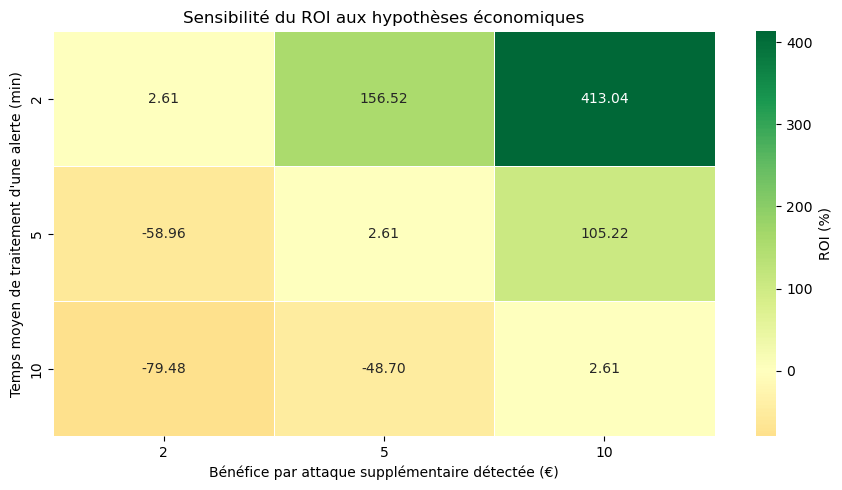

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Organisation des résultats en matrice
matrice_roi = df_sensibilite.pivot(
    index="Temps par alerte (min)",
    columns="Bénéfice par attaque (€)",
    values="ROI (%)"
)

# Création de la carte thermique
plt.figure(figsize=(9, 5))

sns.heatmap(
    matrice_roi,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "ROI (%)"}
)

plt.title("Sensibilité du ROI aux hypothèses économiques")
plt.xlabel("Bénéfice par attaque supplémentaire détectée (€)")
plt.ylabel("Temps moyen de traitement d'une alerte (min)")

plt.tight_layout()
plt.show()


### Interprétation — Visualisation de la sensibilité économique

Cette carte thermique représente les neuf scénarios économiques étudiés.

Les lignes correspondent au temps moyen de traitement d'une alerte, tandis que les colonnes correspondent au bénéfice hypothétique par attaque supplémentaire détectée.

La couleur de chaque case indique le ROI :

- **Rouge :** ROI négatif,
- **Jaune :** ROI proche de zéro,
- **Vert :** ROI positif.

Le graphique montre que la rentabilité théorique du modèle D augmente lorsque le temps de traitement des alertes diminue et lorsque le bénéfice supposé par attaque détectée augmente.

**Conclusion :** le choix du modèle D dépend fortement des conditions opérationnelles. Une automatisation partielle de l'analyse des alertes pourrait réduire les coûts, mais son efficacité devrait être vérifiée expérimentalement.

Les valeurs présentées sont des simulations reposant sur des hypothèses fictives et ne constituent pas des résultats financiers réels.

---


In [8]:
from pathlib import Path

# Dossier des figures du projet
dossier_figures = Path("reports/figures")
dossier_figures.mkdir(parents=True, exist_ok=True)

# Recréation de la carte thermique pour son export
fig, ax = plt.subplots(figsize=(9, 5))

sns.heatmap(
    matrice_roi,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "ROI (%)"},
    ax=ax
)

ax.set_title("Sensibilité du ROI aux hypothèses économiques")
ax.set_xlabel("Bénéfice par attaque supplémentaire détectée (€)")
ax.set_ylabel("Temps moyen de traitement d'une alerte (min)")

plt.tight_layout()

# Enregistrement en haute résolution
chemin_figure = dossier_figures / "sensibilite_roi.png"

fig.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print("Figure enregistrée :", chemin_figure.resolve())
print("Fichier existant :", chemin_figure.is_file())

Figure enregistrée : reports/figures/sensibilite_roi.png
Fichier existant : True



### Exportation de la carte thermique

La carte thermique de l'analyse de sensibilité est enregistrée au format PNG dans le dossier `reports/figures/`.

Le paramètre `dpi=300` permet d'obtenir une image de haute résolution adaptée à une intégration dans le rapport PDF et dans les diapositives.

Le fichier `sensibilite_roi.png` pourra être utilisé pour illustrer l'influence des hypothèses économiques sur la rentabilité théorique du modèle D.

Cette opération ne modifie pas les résultats de l'analyse.

---



## 3. Analyse des risques et des limites

### 3.1. Risques liés aux performances du modèle

**Risque 1 — Attaques non détectées**

Le modèle D présente un rappel de 37,20 %. Il manque donc 62,80 % des attaques présentes dans le jeu de test.

Ces faux négatifs constituent un risque majeur : certaines communications malveillantes pourraient ne générer aucune alerte.

**Risque 2 — Fausses alertes**

Le modèle D signale à tort 2 862 communications normales sur les 56 000 communications normales du jeu de test, soit un taux de fausses alertes d'environ 5,11 %.

Ces alertes peuvent augmenter la charge de travail des analystes et provoquer une fatigue liée aux alertes répétées.

**Risque 3 — Détection inégale selon les catégories d'attaques**

Les résultats du notebook `02_modelisation.ipynb` montrent que le modèle D détecte beaucoup mieux certaines catégories d'attaques que d'autres.

Cette différence limite sa capacité à assurer une surveillance homogène du trafic réseau.

### 3.2. Limites méthodologiques

**Limite 1 — Représentativité des données**

Les performances ont été mesurées sur UNSW-NB15. Elles ne garantissent pas des performances équivalentes sur le trafic d'une entreprise réelle.

**Limite 2 — Apprentissage à partir du trafic normal**

Le modèle D utilise les communications étiquetées comme normales pour construire son profil de référence.

Cette approche de détection de nouveauté exploite donc les étiquettes normales pendant l'entraînement, même si elle n'utilise pas les catégories d'attaques pour apprendre à les reconnaître.

**Limite 3 — Sensibilité au seuil de détection**

Le nombre d'alertes dépend du seuil retenu. Un seuil plus permissif peut détecter davantage d'attaques, mais générer davantage de fausses alertes.

**Limite 4 — Hypothèses économiques**

Les calculs de ROI reposent sur des durées de traitement et des bénéfices fictifs. Ils ne constituent pas une estimation vérifiée des économies réalisées.

### 3.3. Mesures de réduction des risques

Plusieurs mesures peuvent être envisagées :

- utiliser le modèle comme un outil complémentaire de surveillance, et non comme un système de protection autonome,
- faire examiner les alertes par des analystes avant toute action,
- tester le modèle sur des données représentatives du réseau de l'entreprise,
- mesurer les temps réels de traitement et les coûts opérationnels,
- surveiller l'évolution du trafic et réévaluer régulièrement les performances,
- comparer les résultats avec ceux d'autres outils de détection de sécurité.

**Conclusion :** le modèle D présente un intérêt expérimental pour la détection de comportements atypiques, mais ses limites imposent une validation supplémentaire avant toute utilisation opérationnelle.

---



## 4. Recommandation métier finale

### 4.1. Synthèse des résultats

L'étude a permis de comparer plusieurs approches de détection d'anomalies dans le trafic réseau UNSW-NB15.

Les modèles C et D présentent les résultats les plus intéressants parmi les approches évaluées.

Le modèle C détecte **39 409 attaques** avec **560 fausses alertes**, tandis que le modèle D détecte **44 393 attaques** avec **2 862 fausses alertes**.

Le modèle D permet donc de détecter **4 984 attaques supplémentaires**, mais génère **7 286 alertes supplémentaires au total**.

### 4.2. Analyse de la décision

**Sur le plan technique :**

Le modèle D est préférable si l'objectif prioritaire est d'augmenter le nombre d'attaques détectées.

Cependant, son rappel reste limité à **37,20 %**, ce qui signifie que la majorité des attaques du jeu de test ne sont pas détectées.

**Sur le plan opérationnel :**

Le modèle C produit moins de fausses alertes et nécessite moins de temps de vérification.

Le modèle D augmente la charge de traitement des alertes et doit donc être utilisé avec des ressources adaptées.

**Sur le plan économique :**

Avec les hypothèses de 5 minutes de traitement par alerte et de 40 € par heure, le surcoût du modèle D est estimé à **24 286,67 €** sur le volume du jeu de test.

Le modèle D devient théoriquement plus avantageux lorsque le bénéfice moyen associé à chaque attaque supplémentaire détectée dépasse environ **4,87 €**.

Cette rentabilité reste hypothétique, car les bénéfices et les coûts réels ne sont pas connus.

### 4.3. Décision recommandée

**Recommandation : ne pas déployer immédiatement les modèles C ou D comme systèmes autonomes de détection des attaques.**

Leurs performances sont insuffisantes pour garantir une couverture satisfaisante des comportements malveillants.

En revanche, il est possible de retenir le **modèle D comme candidat expérimental pour une phase pilote**, car il détecte davantage d'attaques que le modèle C.

Cette expérimentation devrait être réalisée en complément des dispositifs de sécurité existants, sans déclencher automatiquement d'actions de blocage.

### 4.4. Conditions avant un éventuel déploiement

Avant d'envisager une utilisation opérationnelle, il serait nécessaire de :

1. Tester le modèle sur du trafic réseau représentatif de l'entreprise.
2. Mesurer la qualité des alertes et le temps réel nécessaire à leur traitement.
3. Améliorer la détection des catégories d'attaques actuellement peu reconnues.
4. Comparer les performances avec celles des solutions de sécurité déjà utilisées.
5. Réévaluer les coûts et les bénéfices à partir de données opérationnelles.
6. Définir un processus de supervision humaine et de suivi des performances.

### 4.5. Conclusion générale

Ce projet montre qu'une approche fondée sur K-Means peut identifier certains comportements atypiques dans le trafic réseau.

L'amélioration apportée par le modèle D démontre l'intérêt d'un apprentissage du profil normal et d'une calibration du seuil de détection.

Cependant, **une meilleure performance de détection ne signifie pas automatiquement qu'un modèle est suffisamment fiable ou économiquement rentable pour être déployé**.

La décision finale consiste donc à privilégier une expérimentation contrôlée du modèle D, tout en poursuivant l'amélioration de la détection et l'évaluation des coûts réels.
